In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("netflix_titles.csv")
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


This folder contains the final versions of each visualization. Most final results can not run without their previous cells because changes were made so I added them too.

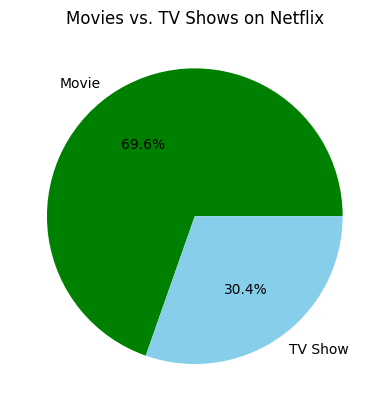

In [ ]:
#Figure 1: Does netflix have more movies or tv shows
type_counts = df["type"].value_counts()

plt.pie(type_counts.values, labels = type_counts.index,
        autopct= "%1.1f%%", colors= ["green", "skyblue"])
plt.title("Movies vs. TV Shows on Netflix")
plt.show()

In [ ]:
#For Figure 2 Separating and counting the genres
genres = []

for item in df["listed_in"]:
  genre_list = item.split(",")

  for genre in genre_list:
    genres.append(genre.strip())

genre_counts = pd.Series(genres).value_counts()
genre_counts.head(10)

,count
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641
Romantic Movies,616


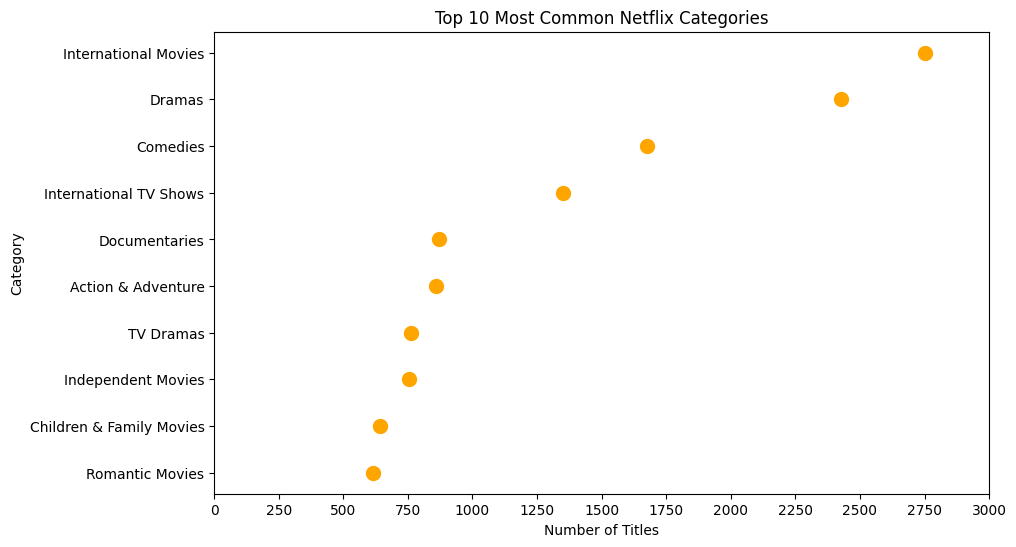

In [ ]:
#Figure 2: The most commonly used genres in Netflix (top 10)
top_genres = genre_counts.head(10)
plt.figure(figsize=(10,6))
plt.scatter(top_genres.values, top_genres.index, color = "orange", s=100)
plt.title("Top 10 Most Common Netflix Categories")
plt.xlabel("Number of Titles")
plt.ylabel("Category")
plt.xticks(range(0, 3001, 250))

plt.gca().invert_yaxis()
plt.show()

In [ ]:
#For Figure 3 Separate and count the countries
countries = []

for item in df["country"]:
  if pd.notna(item):
    country_list = item.split(",")

    for country in country_list:
      countries.append(country.strip())

country_counts = pd.Series(countries).value_counts()
country_counts.head(10)

,count
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393
Japan,318
Spain,232
South Korea,231
Germany,226
Mexico,169


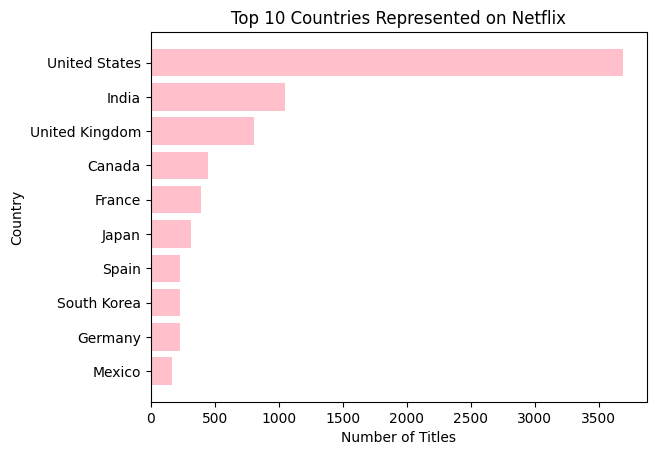

In [ ]:
#Figure 3: The countries with the most titles (Top 10)
top_countries = country_counts.head(10)
plt.barh(top_countries.index, top_countries.values, color = "pink")
plt.title("Top 10 Countries Represented on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Country")

plt.gca().invert_yaxis()
plt.show()

In [ ]:
#For Figure 4 Filtering Movies from TV Shows
movies = df[df["type"] == "Movie"]
movies [["title", "duration"]].head(10)

,title,duration
0,Dick Johnson Is Dead,90 min
6,My Little Pony: A New Generation,91 min
7,Sankofa,125 min
9,The Starling,104 min
12,Je Suis Karl,127 min
13,Confessions of an Invisible Girl,91 min
16,Europe's Most Dangerous Man: Otto Skorzeny in ...,67 min
18,Intrusion,94 min
22,Avvai Shanmughi,161 min
23,Go! Go! Cory Carson: Chrissy Takes the Wheel,61 min


In [ ]:
#Conversion of movie durations in numbers
movies = movies.copy()
movies["duration_minutes"] = movies["duration"].str.replace(" min", "")
movies["duration_minutes"] = pd.to_numeric(movies["duration_minutes"], errors = "coerce")
movies[["title", "duration_minutes"]].head(10)

,title,duration_minutes
0,Dick Johnson Is Dead,90.0
6,My Little Pony: A New Generation,91.0
7,Sankofa,125.0
9,The Starling,104.0
12,Je Suis Karl,127.0
13,Confessions of an Invisible Girl,91.0
16,Europe's Most Dangerous Man: Otto Skorzeny in ...,67.0
18,Intrusion,94.0
22,Avvai Shanmughi,161.0
23,Go! Go! Cory Carson: Chrissy Takes the Wheel,61.0


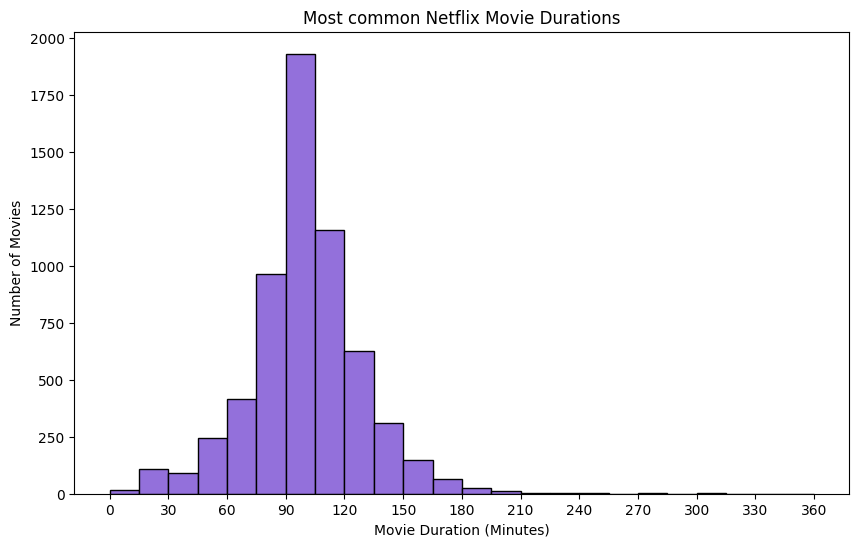

In [ ]:
#Now plotting Figure 4: Most common movie durations on Netflix
plt.figure(figsize=(10,6))
plt.hist(movies["duration_minutes"].dropna(),
         bins=range(0, 361, 15), color="mediumpurple", edgecolor="black")
plt.title("Most common Netflix Movie Durations")
plt.xlabel("Movie Duration (Minutes)")
plt.ylabel("Number of Movies")
plt.xticks(range(0, 361, 30))
plt.show()